# Day 6 – End-to-End ML Pipeline & Business Insights

## Objective
Bring together the existing Day 2–Day 5 work and translate measured results into practical business insights.

**Workflow:** Raw Data → Cleaning → Feature Engineering → Modeling/Evaluation → Prediction → Business Insight

This notebook reuses the existing segmentation, sentiment, delivery prediction, and demand forecasting outputs. It does not pretend that these different tasks are one model. Where saved outputs are missing, the notebook reports that clearly rather than inventing results.

### Components
1. Customer and restaurant segmentation
2. Customer review sentiment analysis
3. Delivery-time prediction
4. Hourly demand forecasting

**Important:** The data is synthetic. Findings are useful for this educational project, not proof of real-world Uber Eats performance.

## 1. Setup and project paths

This notebook supports being opened from either the project root or the `notebooks/` folder. It loads existing files and creates a processed-output folder when needed.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

ROOT_CANDIDATES = [Path("."), Path("..")]
PROJECT_ROOT = next(
    (p.resolve() for p in ROOT_CANDIDATES if (p / "data").exists()),
    Path(".").resolve()
)

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data folder exists:", RAW_DIR.exists())
print("Processed data folder:", PROCESSED_DIR)

Project root: /home/nineleaps/Desktop/ML_Assignment
Raw data folder exists: True
Processed data folder: /home/nineleaps/Desktop/ML_Assignment/data/processed


## 2. Load existing data and outputs

The notebook loads only files that exist. This allows the workflow to run even if a particular optional output was not saved. Missing components will be listed in the final limitations section.

In [2]:
def read_csv_if_exists(path):
    if path.exists():
        try:
            return pd.read_csv(path)
        except Exception as error:
            print(f"Could not read {path.name}: {error}")
    else:
        print(f"Not found (optional): {path.relative_to(PROJECT_ROOT)}")
    return None

customers = read_csv_if_exists(RAW_DIR / "customers.csv")
restaurants = read_csv_if_exists(RAW_DIR / "restaurants.csv")
orders = read_csv_if_exists(RAW_DIR / "orders.csv")
deliveries = read_csv_if_exists(RAW_DIR / "deliveries.csv")
reviews = read_csv_if_exists(RAW_DIR / "reviews.csv")
payments = read_csv_if_exists(RAW_DIR / "payments.csv")
drivers = read_csv_if_exists(RAW_DIR / "drivers.csv")

customer_segments = read_csv_if_exists(PROCESSED_DIR / "customer_segmentation_results.csv")
restaurant_segments = read_csv_if_exists(PROCESSED_DIR / "restaurant_segmentation_results.csv")
delivery_model_comparison = read_csv_if_exists(PROCESSED_DIR / "delivery_time_model_comparison.csv")
delivery_features = read_csv_if_exists(PROCESSED_DIR / "delivery_time_feature_engineered.csv")
demand_model_comparison = read_csv_if_exists(PROCESSED_DIR / "demand_forecast_model_comparison.csv")
hourly_demand = read_csv_if_exists(PROCESSED_DIR / "hourly_demand.csv")
forecast_results = read_csv_if_exists(PROCESSED_DIR / "final_hourly_demand_forecast.csv")
adf_results = read_csv_if_exists(PROCESSED_DIR / "adf_test_results.csv")

loaded = {
    "customers": customers, "restaurants": restaurants, "orders": orders,
    "deliveries": deliveries, "reviews": reviews, "payments": payments,
    "drivers": drivers, "customer_segments": customer_segments,
    "restaurant_segments": restaurant_segments,
    "delivery_model_comparison": delivery_model_comparison,
    "delivery_features": delivery_features,
    "demand_model_comparison": demand_model_comparison,
    "hourly_demand": hourly_demand, "forecast_results": forecast_results,
    "adf_results": adf_results
}

inventory = pd.DataFrame([
    {"dataset": name, "loaded": frame is not None,
     "rows": len(frame) if frame is not None else None,
     "columns": len(frame.columns) if frame is not None else None}
    for name, frame in loaded.items()
])
display(inventory)

,dataset,loaded,rows,columns
0,customers,True,500,5
1,restaurants,True,100,6
2,orders,True,10000,9
3,deliveries,True,9004,7
4,reviews,True,5853,4
5,payments,True,10000,5
6,drivers,True,150,5
7,customer_segments,True,500,11
8,restaurant_segments,True,100,10
9,delivery_model_comparison,True,4,4


## 3. Cleaning and feature engineering

This section standardizes column names and parses relevant timestamps. It avoids changing the original raw files.

In [3]:
def clean_column_names(frame):
    frame = frame.copy()
    frame.columns = (
        frame.columns.astype(str).str.strip().str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    return frame

for name in ["customers", "restaurants", "orders", "deliveries", "reviews",
             "payments", "drivers", "customer_segments", "restaurant_segments",
             "delivery_model_comparison", "delivery_features",
             "demand_model_comparison", "hourly_demand", "forecast_results",
             "adf_results"]:
    frame = loaded.get(name)
    if frame is not None:
        loaded[name] = clean_column_names(frame)

customers = loaded["customers"]
restaurants = loaded["restaurants"]
orders = loaded["orders"]
deliveries = loaded["deliveries"]
reviews = loaded["reviews"]
payments = loaded["payments"]
drivers = loaded["drivers"]
customer_segments = loaded["customer_segments"]
restaurant_segments = loaded["restaurant_segments"]
delivery_model_comparison = loaded["delivery_model_comparison"]
delivery_features = loaded["delivery_features"]
demand_model_comparison = loaded["demand_model_comparison"]
hourly_demand = loaded["hourly_demand"]
forecast_results = loaded["forecast_results"]
adf_results = loaded["adf_results"]

if orders is not None:
    for col in ["order_timestamp", "order_date"]:
        if col in orders.columns:
            orders[col] = pd.to_datetime(orders[col], errors="coerce")

if hourly_demand is not None and "order_timestamp" in hourly_demand.columns:
    hourly_demand["order_timestamp"] = pd.to_datetime(
        hourly_demand["order_timestamp"], errors="coerce"
    )

if forecast_results is not None:
    for col in ["timestamp", "ds"]:
        if col in forecast_results.columns:
            forecast_results[col] = pd.to_datetime(forecast_results[col], errors="coerce")

print("Cleaning and timestamp preparation complete.")

Cleaning and timestamp preparation complete.


## 4. Customer segmentation insights

We use the saved customer cluster assignments and profiles from Day 2. Spending and order activity are treated as value indicators, not as guaranteed future value.

In [4]:
customer_profile = None

if customer_segments is not None and "cluster" in customer_segments.columns:
    customer_segments["cluster"] = pd.to_numeric(customer_segments["cluster"], errors="coerce")
    numeric_candidates = [
        col for col in [
            "total_orders", "avg_order_value", "total_spending",
            "ordering_frequency", "weekend_orders", "late_night_orders",
            "avg_rating_given"
        ] if col in customer_segments.columns
    ]
    if numeric_candidates:
        customer_profile = customer_segments.groupby("cluster").agg(
            customer_count=("cluster", "size"),
            **{f"avg_{col}": (col, "mean") for col in numeric_candidates}
        ).reset_index()
        display(customer_profile.round(2))

        if "avg_total_spending" in customer_profile.columns:
            customer_profile = customer_profile.sort_values(
                "avg_total_spending", ascending=False
            )
            display(customer_profile.round(2))
            top_customer_cluster = customer_profile.iloc[0]
            print(
                f"Highest average spending cluster: {int(top_customer_cluster['cluster'])} "
                f"(average spending {top_customer_cluster['avg_total_spending']:.2f})."
            )
    else:
        print("Customer segment file is present, but expected value columns are missing.")
else:
    print("Customer segmentation output is unavailable. Run Day 2 and save its results first.")

,cluster,customer_count,avg_total_orders,avg_avg_order_value,avg_total_spending,avg_ordering_frequency,avg_weekend_orders,avg_late_night_orders,avg_avg_rating_given
0,0,20,22.90,788.24,18052.58,17.05,7.80,6.45,3.44
1,1,260,17.09,742.78,12618.33,1.14,4.58,4.63,3.71
2,2,220,23.17,774.05,17878.37,1.60,7.04,7.14,3.76


,cluster,customer_count,avg_total_orders,avg_avg_order_value,avg_total_spending,avg_ordering_frequency,avg_weekend_orders,avg_late_night_orders,avg_avg_rating_given
0,0,20,22.90,788.24,18052.58,17.05,7.80,6.45,3.44
2,2,220,23.17,774.05,17878.37,1.60,7.04,7.14,3.76
1,1,260,17.09,742.78,12618.33,1.14,4.58,4.63,3.71


Highest average spending cluster: 0 (average spending 18052.58).


### Customer business interpretation

The highest-spending cluster is a candidate for retention offers and service monitoring. A cluster with many customers may be important for broad engagement, even if its average spend is lower. Segment labels describe patterns in this dataset and should not be treated as permanent customer identities.

## 5. Restaurant segmentation insights

We compare segment-level revenue, ratings, delivery time, and cancellation rates where those columns are available.

In [5]:
restaurant_profile = None

if restaurant_segments is not None and "cluster" in restaurant_segments.columns:
    numeric_candidates = [
        col for col in [
            "total_orders", "revenue", "avg_rating",
            "cancellation_rate", "avg_delivery_time", "avg_prep_time"
        ] if col in restaurant_segments.columns
    ]
    if numeric_candidates:
        restaurant_profile = restaurant_segments.groupby("cluster").agg(
            restaurant_count=("cluster", "size"),
            **{f"avg_{col}": (col, "mean") for col in numeric_candidates}
        ).reset_index()
        display(restaurant_profile.round(2))

        if "avg_revenue" in restaurant_profile.columns:
            print("Highest average revenue cluster:")
            display(restaurant_profile.nlargest(1, "avg_revenue").round(2))
        if "avg_avg_rating" in restaurant_profile.columns:
            print("Lowest average rating cluster:")
            display(restaurant_profile.nsmallest(1, "avg_avg_rating").round(2))
        if "avg_avg_delivery_time" in restaurant_profile.columns:
            print("Longest average delivery-time cluster:")
            display(restaurant_profile.nlargest(1, "avg_avg_delivery_time").round(2))
    else:
        print("Restaurant segment file is present, but expected profile columns are missing.")
else:
    print("Restaurant segmentation output is unavailable. Run Day 2 and save its results first.")

,cluster,restaurant_count,avg_total_orders,avg_revenue,avg_avg_rating,avg_cancellation_rate,avg_avg_delivery_time,avg_avg_prep_time
0,0,24,93.54,69106.92,3.82,9.09,63.17,28.33
1,1,20,94.20,72596.58,3.73,6.37,49.57,15.10
2,2,19,104.21,78760.67,3.83,5.83,69.58,35.37
3,3,19,112.47,86523.59,3.72,7.00,54.54,20.63
4,4,18,97.44,73564.47,3.48,6.03,64.95,30.17


Highest average revenue cluster:


,cluster,restaurant_count,avg_total_orders,avg_revenue,avg_avg_rating,avg_cancellation_rate,avg_avg_delivery_time,avg_avg_prep_time
3,3,19,112.47,86523.59,3.72,7.0,54.54,20.63


Lowest average rating cluster:


,cluster,restaurant_count,avg_total_orders,avg_revenue,avg_avg_rating,avg_cancellation_rate,avg_avg_delivery_time,avg_avg_prep_time
4,4,18,97.44,73564.47,3.48,6.03,64.95,30.17


Longest average delivery-time cluster:


,cluster,restaurant_count,avg_total_orders,avg_revenue,avg_avg_rating,avg_cancellation_rate,avg_avg_delivery_time,avg_avg_prep_time
2,2,19,104.21,78760.67,3.83,5.83,69.58,35.37


### Restaurant business interpretation

Prioritize investigation of segments that combine low ratings with high cancellation rates or long delivery times. High-revenue restaurants with long delivery times may need operational review so that revenue performance does not hide a poor customer experience. These are screening signals, not proof that the restaurant itself causes delays.

## 6. Customer review sentiment

The notebook summarizes saved VADER sentiment labels if available. It also checks common review phrases so the business discussion can be grounded in actual text rather than assumptions.

In [6]:
sentiment_summary = None

if reviews is not None and "review_text" in reviews.columns:
    reviews["review_text"] = reviews["review_text"].fillna("").astype(str)
    print("Review rows:", len(reviews))
    print("Unique review text templates:", reviews["review_text"].nunique())

    sentiment_col = next(
        (col for col in ["vader_sentiment", "sentiment", "text_sentiment"]
         if col in reviews.columns),
        None
    )

    if sentiment_col:
        sentiment_summary = (
            reviews[sentiment_col].value_counts(dropna=False)
            .rename_axis("sentiment").reset_index(name="review_count")
        )
        sentiment_summary["percentage"] = (
            sentiment_summary["review_count"] / len(reviews) * 100
        ).round(2)
        display(sentiment_summary)

    keywords = {
        "delivery delay": ["late", "delay", "too long", "slow"],
        "food temperature/quality": ["cold", "stale", "quality", "taste"],
        "missing/wrong items": ["missing", "wrong item", "incorrect"],
        "packaging": ["packaging", "spill", "leak", "damaged"],
        "positive service/value": ["friendly", "good value", "great", "excellent"]
    }

    theme_rows = []
    lower_text = reviews["review_text"].str.lower()
    for theme, words in keywords.items():
        count = lower_text.apply(
            lambda text: any(word in text for word in words)
        ).sum()
        theme_rows.append({
            "theme": theme,
            "reviews_matching_theme": int(count),
            "percentage_of_reviews": round(count / len(reviews) * 100, 2)
        })

    review_themes = pd.DataFrame(theme_rows).sort_values(
        "reviews_matching_theme", ascending=False
    )
    display(review_themes)
else:
    print("Reviews data is unavailable or does not contain review_text.")

Review rows: 5853
Unique review text templates: 10


,theme,reviews_matching_theme,percentage_of_reviews
0,delivery delay,1151,19.67
4,positive service/value,1123,19.19
1,food temperature/quality,1115,19.05
3,packaging,611,10.44
2,missing/wrong items,598,10.22


### Sentiment interpretation and limitations

Keyword matches are a simple theme scan, not a trained topic model. One review can match multiple themes, and words may be used in different contexts. The Day 3 notebook showed that the review text contains repeated templates, so sentiment and classification results should be validated on more varied, independently labeled reviews before being used operationally.

## 7. Delivery-time model comparison

We use the saved Day 4 evaluation results when available. This section also reports which features are present in the engineered dataset. Feature presence alone does not prove causal influence.

In [7]:
if delivery_model_comparison is not None:
    display(delivery_model_comparison)
else:
    print("Delivery model comparison file is unavailable.")

if delivery_features is not None:
    print("Delivery feature dataset shape:", delivery_features.shape)
    print("Available columns:")
    print(delivery_features.columns.tolist())

    target_candidates = [
        col for col in delivery_features.columns
        if col in ["delivery_time_minutes", "delivery_duration_minutes"]
    ]
    if target_candidates:
        target_col = target_candidates[0]
        delivery_features[target_col] = pd.to_numeric(
            delivery_features[target_col], errors="coerce"
        )
        print("Delivery-time target summary:")
        display(delivery_features[target_col].describe().to_frame().round(2))
else:
    print("Delivery feature dataset is unavailable.")

,model,mae_minutes,rmse_minutes,r2
0,Lasso Regression,4.141360,5.209538,0.908357
1,Random Forest,4.448277,5.591654,0.894420
2,Ridge Regression,4.463092,5.635322,0.892764
3,Baseline (training mean),13.988133,17.209816,-0.000123


Delivery feature dataset shape: (9004, 24)
Available columns:
['distance_km', 'traffic_level', 'weather', 'order_timestamp', 'order_amount', 'num_items', 'order_hour', 'order_date', 'age', 'gender', 'city', 'signup_date', 'restaurant_name', 'cuisine', 'city_restaurants', 'restaurant_rating', 'average_prep_time_minutes', 'vehicle_type', 'driver_rating', 'experience_months', 'city_drivers', 'order_day_of_week', 'is_weekend', 'delivery_time_minutes']
Delivery-time target summary:


,delivery_time_minutes
count,9004.00
mean,60.33
std,16.98
min,10.00
25%,48.00
50%,60.00
75%,73.00
max,120.00


### Delivery model interpretation

Use the held-out test MAE, RMSE, and R² from Day 4 to compare models. MAE gives the average absolute prediction error in minutes. RMSE penalizes larger errors more heavily. R² describes how much variation is explained relative to a mean-only prediction baseline.

The Day 4 results previously observed in the notebook showed Lasso as the best model by test MAE (about 4.14 minutes) and a test R² of about 0.908. The cells below use the saved comparison file as the source of truth when it is available.

In [8]:
if delivery_model_comparison is not None:
    # Normalize common metric labels for a simple ranking where possible.
    comparison = delivery_model_comparison.copy()
    print("Saved Day 4 model comparison:")
    display(comparison)

    mae_col = next(
        (c for c in comparison.columns if "mae" in c.lower() and "cv" not in c.lower()),
        None
    )
    if mae_col:
        best_delivery = comparison.loc[pd.to_numeric(comparison[mae_col], errors="coerce").idxmin()]
        print(f"Lowest saved MAE model: {best_delivery.iloc[0]}")
        print(f"MAE value: {best_delivery[mae_col]}")
else:
    print("No saved model comparison available to rank.")

Saved Day 4 model comparison:


,model,mae_minutes,rmse_minutes,r2
0,Lasso Regression,4.141360,5.209538,0.908357
1,Random Forest,4.448277,5.591654,0.894420
2,Ridge Regression,4.463092,5.635322,0.892764
3,Baseline (training mean),13.988133,17.209816,-0.000123


Lowest saved MAE model: Lasso Regression
MAE value: 4.141359901342187


### Feature importance

If a feature-importance table was not saved by Day 4, we do not fabricate one. The next cell provides a cautious correlation scan from the saved engineered features, where numeric columns are available. Correlation is not causation and can be affected by confounding or leakage.

In [9]:
if delivery_features is not None:
    target_col = next(
        (c for c in ["delivery_time_minutes", "delivery_duration_minutes"]
         if c in delivery_features.columns),
        None
    )
    if target_col:
        numeric = delivery_features.select_dtypes(include=np.number)
        if target_col in numeric.columns and numeric.shape[1] > 1:
            correlations = (
                numeric.corr(numeric_only=True)[target_col]
                .drop(labels=[target_col], errors="ignore")
                .dropna()
                .sort_values(key=lambda s: s.abs(), ascending=False)
                .rename("correlation_with_delivery_time")
                .to_frame()
            )
            display(correlations.head(15).round(3))
            print("Interpret these correlations as associations, not causes.")
        else:
            print("Not enough numeric columns for a correlation scan.")
    else:
        print("Delivery-time target column was not found in the saved features.")
else:
    print("Skipping feature analysis because the delivery feature file is unavailable.")

,correlation_with_delivery_time
distance_km,0.717
average_prep_time_minutes,0.498
restaurant_rating,0.026
is_weekend,0.020
experience_months,0.014
order_day_of_week,0.014
driver_rating,-0.012
num_items,0.004
age,0.003
order_hour,-0.002


Interpret these correlations as associations, not causes.


## 8. Hourly demand forecasting

We compare the saved baseline, ARIMA, and Prophet results and inspect actual demand patterns. Forecast metrics are used as a guide, not as a guarantee of future demand.

,model,mae,rmse
0,Baseline,0.423241,0.522367
1,ARIMA,0.423237,0.522367
2,Prophet,0.418756,0.522363


Hourly observations: 35063
Mean orders per hour: 0.285
Zero-order hours (%): 75.06
Top 5 hours by total orders:


,total_orders
hour,
8,446
2,442
7,432
13,430
11,426


Total orders by day of week:


,total_orders
day_name,
Monday,1377
Tuesday,1435
Wednesday,1429
Thursday,1409
Friday,1453
Saturday,1469
Sunday,1428


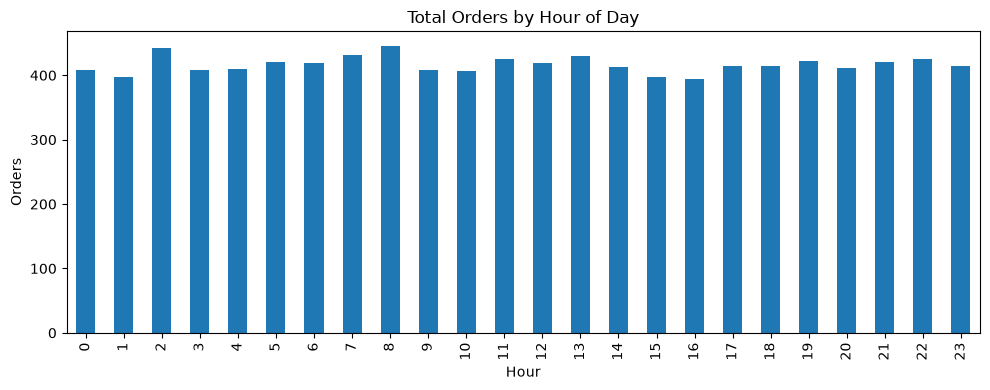

In [10]:
if demand_model_comparison is not None:
    display(demand_model_comparison)
else:
    print("Demand forecast comparison file is unavailable.")

if hourly_demand is not None:
    timestamp_col = next(
        (c for c in ["order_timestamp", "timestamp", "ds"] if c in hourly_demand.columns),
        None
    )
    count_col = next(
        (c for c in ["order_count", "orders", "y"] if c in hourly_demand.columns),
        None
    )

    if timestamp_col and count_col:
        hourly_demand[timestamp_col] = pd.to_datetime(
            hourly_demand[timestamp_col], errors="coerce"
        )
        hourly_demand[count_col] = pd.to_numeric(
            hourly_demand[count_col], errors="coerce"
        )
        demand = hourly_demand.dropna(subset=[timestamp_col, count_col]).copy()
        demand["hour"] = demand[timestamp_col].dt.hour
        demand["day_name"] = demand[timestamp_col].dt.day_name()
        demand["is_weekend"] = demand[timestamp_col].dt.dayofweek >= 5

        print("Hourly observations:", len(demand))
        print("Mean orders per hour:", round(demand[count_col].mean(), 3))
        print("Zero-order hours (%):", round((demand[count_col].eq(0).mean()) * 100, 2))

        hourly_profile = demand.groupby("hour")[count_col].sum().sort_values(ascending=False)
        print("Top 5 hours by total orders:")
        display(hourly_profile.head(5).rename("total_orders").to_frame())

        weekday_profile = demand.groupby("day_name")[count_col].sum().reindex([
            "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
        ])
        print("Total orders by day of week:")
        display(weekday_profile.rename("total_orders").to_frame())

        plt.figure(figsize=(10, 4))
        hourly_profile.sort_index().plot(kind="bar")
        plt.title("Total Orders by Hour of Day")
        plt.xlabel("Hour")
        plt.ylabel("Orders")
        plt.tight_layout()
        plt.show()
    else:
        print("Hourly demand file does not have recognizable timestamp/count columns.")
else:
    print("Hourly demand file is unavailable.")

### Forecast evaluation and operational meaning

The Day 5 results showed Prophet with a slightly lower MAE than the baseline and ARIMA, while RMSE was effectively identical. The forecasts stayed close to the average and missed short-term spikes. Because approximately 75% of hourly observations were zero, a near-average forecast can look reasonable under aggregate error metrics but still be poor at identifying peak periods.

Forecast result columns: ['timestamp', 'actual_orders', 'baseline_forecast', 'arima_forecast', 'prophet_forecast']


,timestamp,actual_orders,baseline_forecast,arima_forecast,prophet_forecast
0,2025-03-14 18:00:00,0,0.288414,0.287949,0.284134
1,2025-03-14 19:00:00,0,0.288414,0.285049,0.294659
2,2025-03-14 20:00:00,0,0.288414,0.287558,0.296426
3,2025-03-14 21:00:00,1,0.288414,0.287809,0.290061
4,2025-03-14 22:00:00,0,0.288414,0.288165,0.283139


,model_or_forecast,MAE,RMSE
0,baseline_forecast,0.4232,0.5224
1,arima_forecast,0.4232,0.5224
2,prophet_forecast,0.4188,0.5224


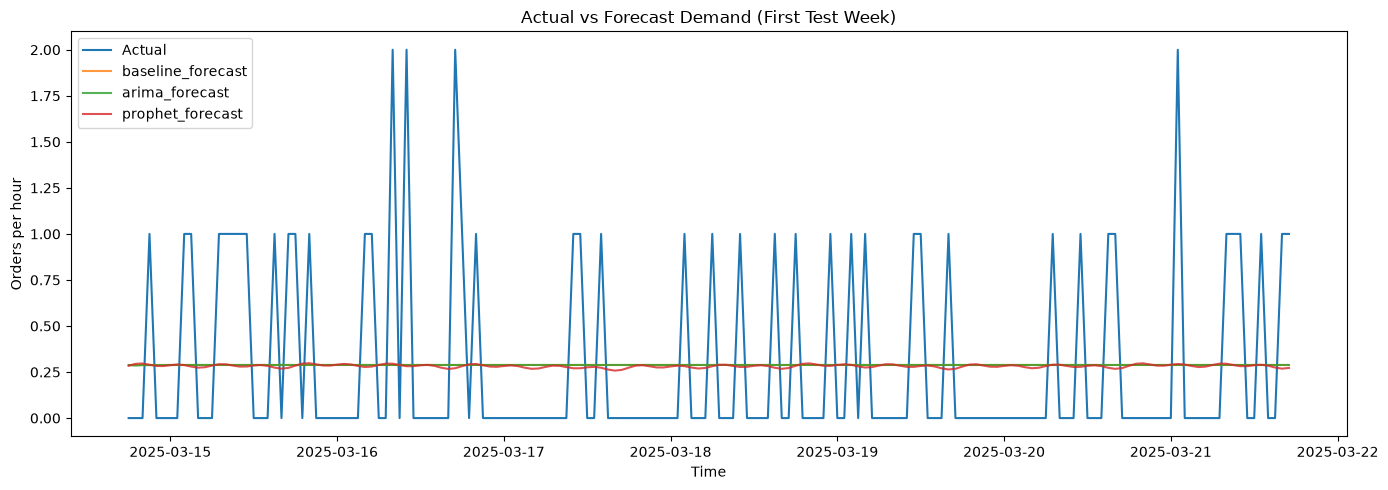

In [11]:
if forecast_results is not None:
    print("Forecast result columns:", forecast_results.columns.tolist())
    display(forecast_results.head())

    actual_col = next(
        (c for c in ["actual_orders", "actual", "order_count"] if c in forecast_results.columns),
        None
    )
    forecast_cols = [
        c for c in forecast_results.columns
        if "forecast" in c.lower() and c != actual_col
    ]
    time_col = next(
        (c for c in ["timestamp", "ds", "order_timestamp"] if c in forecast_results.columns),
        None
    )

    if actual_col and forecast_cols:
        for col in [actual_col] + forecast_cols:
            forecast_results[col] = pd.to_numeric(forecast_results[col], errors="coerce")
        metrics_rows = []
        for col in forecast_cols:
            valid = forecast_results[[actual_col, col]].dropna()
            if len(valid):
                metrics_rows.append({
                    "model_or_forecast": col,
                    "MAE": np.mean(np.abs(valid[actual_col] - valid[col])),
                    "RMSE": np.sqrt(np.mean((valid[actual_col] - valid[col]) ** 2))
                })
        display(pd.DataFrame(metrics_rows).round(4))

        if time_col:
            forecast_results[time_col] = pd.to_datetime(
                forecast_results[time_col], errors="coerce"
            )
            plot_df = forecast_results.dropna(subset=[time_col, actual_col]).head(168)
            plt.figure(figsize=(14, 5))
            plt.plot(plot_df[time_col], plot_df[actual_col], label="Actual", linewidth=1.5)
            for col in forecast_cols:
                plt.plot(plot_df[time_col], plot_df[col], label=col, alpha=0.8)
            plt.title("Actual vs Forecast Demand (First Test Week)")
            plt.xlabel("Time")
            plt.ylabel("Orders per hour")
            plt.legend()
            plt.tight_layout()
            plt.show()
    else:
        print("Actual and forecast columns could not be identified.")
else:
    print("Forecast result file is unavailable.")

## 9. Integrated model comparison summary

Each component solves a different task, so metrics are not directly comparable across components. This summary records the purpose, current evidence, and the key caution for each component.

In [12]:
summary_rows = [
    {
        "component": "Customer segmentation",
        "task": "Unsupervised clustering",
        "evidence": "Saved customer cluster labels and profiles",
        "business_use": "Retention and customer engagement prioritization",
        "main_caution": "Clusters are descriptive and depend on selected features and scaling"
    },
    {
        "component": "Restaurant segmentation",
        "task": "Unsupervised clustering",
        "evidence": "Saved restaurant cluster labels and profiles",
        "business_use": "Identify groups for operational review",
        "main_caution": "A cluster pattern does not prove the cause of poor performance"
    },
    {
        "component": "Sentiment analysis",
        "task": "Text sentiment classification",
        "evidence": "VADER counts and Day 3 classifier results",
        "business_use": "Monitor common customer complaints",
        "main_caution": "Repeated templates and class imbalance limit generalization"
    },
    {
        "component": "Delivery-time prediction",
        "task": "Regression",
        "evidence": "Saved Day 4 MAE, RMSE, and R-squared",
        "business_use": "Estimate delivery duration and review operational risk",
        "main_caution": "Predictions depend on input feature quality and may not establish causes"
    },
    {
        "component": "Demand forecasting",
        "task": "Hourly time-series forecasting",
        "evidence": "Saved baseline, ARIMA, and Prophet metrics",
        "business_use": "Support capacity planning",
        "main_caution": "Forecasts were nearly flat and did not capture demand spikes well"
    }
]
model_summary = pd.DataFrame(summary_rows)
display(model_summary)
model_summary.to_csv(PROCESSED_DIR / "day6_model_comparison_summary.csv", index=False)
print("Saved:", PROCESSED_DIR / "day6_model_comparison_summary.csv")

,component,task,evidence,business_use,main_caution
0,Customer segmentation,Unsupervised clustering,Saved customer cluster labels and profiles,Retention and customer engagement prioritization,Clusters are descriptive and depend on selecte...
1,Restaurant segmentation,Unsupervised clustering,Saved restaurant cluster labels and profiles,Identify groups for operational review,A cluster pattern does not prove the cause of ...
2,Sentiment analysis,Text sentiment classification,VADER counts and Day 3 classifier results,Monitor common customer complaints,Repeated templates and class imbalance limit g...
3,Delivery-time prediction,Regression,"Saved Day 4 MAE, RMSE, and R-squared",Estimate delivery duration and review operatio...,Predictions depend on input feature quality an...
4,Demand forecasting,Hourly time-series forecasting,"Saved baseline, ARIMA, and Prophet metrics",Support capacity planning,Forecasts were nearly flat and did not capture...


Saved: /home/nineleaps/Desktop/ML_Assignment/data/processed/day6_model_comparison_summary.csv


## 10. Data-backed business insights

The following table summarizes conclusions supported by the saved analysis. The notebook fills in numeric evidence from the available files where possible. Recommendations are framed as actions to test, not guaranteed outcomes.

In [13]:
insight_rows = []

# Customer insight
if customer_profile is not None and "avg_total_spending" in customer_profile.columns:
    top = customer_profile.sort_values("avg_total_spending", ascending=False).iloc[0]
    insight_rows.append({
        "business_question": "Which customer segment appears most valuable?",
        "evidence": f"Cluster {int(top['cluster'])} has the highest average total spending "
                    f"({top['avg_total_spending']:.2f} per customer).",
        "recommended_action": "Test targeted retention and loyalty offers for this segment; compare repeat orders and margin before scaling.",
        "confidence_or_caveat": "Spending is a proxy for value; profitability and future retention were not measured here."
    })

# Restaurant insight
if restaurant_profile is not None:
    if "avg_avg_rating" in restaurant_profile.columns:
        low = restaurant_profile.sort_values("avg_avg_rating").iloc[0]
        insight_rows.append({
            "business_question": "Which restaurant segment may need intervention?",
            "evidence": f"Cluster {int(low['cluster'])} has the lowest average rating "
                        f"({low['avg_avg_rating']:.2f}).",
            "recommended_action": "Review review themes, cancellations, preparation time, and delivery time for restaurants in this segment.",
            "confidence_or_caveat": "Segment averages do not identify the cause; inspect restaurant-level records before action."
        })
    if "avg_avg_delivery_time" in restaurant_profile.columns:
        slow = restaurant_profile.sort_values("avg_avg_delivery_time", ascending=False).iloc[0]
        insight_rows.append({
            "business_question": "Which restaurant segment has the longest delivery time?",
            "evidence": f"Cluster {int(slow['cluster'])} has the highest average delivery time "
                        f"({slow['avg_avg_delivery_time']:.2f} minutes).",
            "recommended_action": "Audit preparation and handoff processes for this segment and check whether longer distances explain the difference.",
            "confidence_or_caveat": "Delivery duration may reflect driver availability, distance, weather, or other factors not represented here."
        })

# Review themes
if reviews is not None and "review_text" in reviews.columns:
    lower_text = reviews["review_text"].fillna("").astype(str).str.lower()
    delay_matches = lower_text.apply(
        lambda text: any(word in text for word in ["late", "delay", "too long", "slow"])
    ).sum()
    quality_matches = lower_text.apply(
        lambda text: any(word in text for word in ["cold", "stale", "quality", "taste"])
    ).sum()
    theme_name, theme_count = (
        ("delivery delay", delay_matches)
        if delay_matches >= quality_matches
        else ("food temperature/quality", quality_matches)
    )
    insight_rows.append({
        "business_question": "What customer-experience theme should be investigated first?",
        "evidence": f"Simple keyword scan found {int(delay_matches)} reviews mentioning delay-related terms "
                    f"and {int(quality_matches)} mentioning food-quality/temperature terms.",
        "recommended_action": "Manually review a sample of matching negative reviews and categorize root causes before selecting an intervention.",
        "confidence_or_caveat": "Keyword matching is approximate and themes may overlap; this is not causal evidence."
    })

# Delivery prediction
if delivery_model_comparison is not None:
    mae_col = next(
        (c for c in delivery_model_comparison.columns if "mae" in c.lower() and "cv" not in c.lower()),
        None
    )
    model_col = next(
        (c for c in delivery_model_comparison.columns if c.lower() in ["model", "model_name"]),
        delivery_model_comparison.columns[0] if len(delivery_model_comparison.columns) else None
    )
    if mae_col and model_col:
        valid = delivery_model_comparison.copy()
        valid[mae_col] = pd.to_numeric(valid[mae_col], errors="coerce")
        valid = valid.dropna(subset=[mae_col])
        if not valid.empty:
            best = valid.loc[valid[mae_col].idxmin()]
            insight_rows.append({
                "business_question": "How accurate is delivery-time prediction?",
                "evidence": f"{best[model_col]} has the lowest saved MAE ({best[mae_col]:.2f} in the reported units).",
                "recommended_action": "Use predictions as planning estimates and monitor errors by distance, time period, and restaurant.",
                "confidence_or_caveat": "The model predicts duration; feature associations do not establish causes of delays."
            })

# Demand
if demand_model_comparison is not None:
    mae_col = next(
        (c for c in demand_model_comparison.columns if "mae" in c.lower()),
        None
    )
    model_col = next(
        (c for c in demand_model_comparison.columns if c.lower() in ["model", "model_name"]),
        demand_model_comparison.columns[0] if len(demand_model_comparison.columns) else None
    )
    if mae_col and model_col:
        valid = demand_model_comparison.copy()
        valid[mae_col] = pd.to_numeric(valid[mae_col], errors="coerce")
        valid = valid.dropna(subset=[mae_col])
        if not valid.empty:
            best = valid.loc[valid[mae_col].idxmin()]
            insight_rows.append({
                "business_question": "When should capacity planning use extra caution?",
                "evidence": f"{best[model_col]} has the lowest saved MAE ({best[mae_col]:.4f}); Day 5 analysis found many zero-order hours and forecasts close to the average.",
                "recommended_action": "Use historical hourly/day-of-week patterns as an initial guide, validate peak periods, and run a small capacity pilot before making large staffing changes.",
                "confidence_or_caveat": "The forecast did not capture spikes well and the current hourly dataset is sparse."
            })

business_insights = pd.DataFrame(insight_rows)
if not business_insights.empty:
    display(business_insights)
    business_insights.to_csv(PROCESSED_DIR / "day6_business_insights.csv", index=False)
    print("Saved:", PROCESSED_DIR / "day6_business_insights.csv")
else:
    print("No insight rows could be created from available outputs. Check the inventory in Section 2.")

,business_question,evidence,recommended_action,confidence_or_caveat
0,Which customer segment appears most valuable?,Cluster 0 has the highest average total spendi...,Test targeted retention and loyalty offers for...,Spending is a proxy for value; profitability a...
1,Which restaurant segment may need intervention?,Cluster 4 has the lowest average rating (3.48).,"Review review themes, cancellations, preparati...",Segment averages do not identify the cause; in...
2,Which restaurant segment has the longest deliv...,Cluster 2 has the highest average delivery tim...,Audit preparation and handoff processes for th...,Delivery duration may reflect driver availabil...
3,What customer-experience theme should be inves...,Simple keyword scan found 1151 reviews mention...,Manually review a sample of matching negative ...,Keyword matching is approximate and themes may...
4,How accurate is delivery-time prediction?,Lasso Regression has the lowest saved MAE (4.1...,Use predictions as planning estimates and moni...,The model predicts duration; feature associati...
5,When should capacity planning use extra caution?,Prophet has the lowest saved MAE (0.4188); Day...,Use historical hourly/day-of-week patterns as ...,The forecast did not capture spikes well and t...


Saved: /home/nineleaps/Desktop/ML_Assignment/data/processed/day6_business_insights.csv


## 11. Business recommendations

These recommendations are linked to observed patterns and should be tested before broad deployment.

In [14]:
recommendations = pd.DataFrame([
    {
        "priority": "High",
        "recommendation": "Investigate low-rated restaurant segments",
        "data_basis": "Day 2 restaurant profiles provide average rating, revenue, and delivery-time measures by cluster.",
        "next_step": "Inspect restaurant-level ratings, cancellation rates, preparation time, and review text within the lowest-rated cluster.",
        "success_measure": "Change in rating, cancellation rate, and repeat orders after intervention."
    },
    {
        "priority": "High",
        "recommendation": "Review delivery-delay complaints",
        "data_basis": "Day 3 review text can be scanned for delay-related and food-quality terms.",
        "next_step": "Manually validate a sample of negative reviews and label root causes such as late delivery, cold food, missing items, and packaging.",
        "success_measure": "Reduction in validated complaint rates and improvement in customer ratings."
    },
    {
        "priority": "High",
        "recommendation": "Use delivery predictions as estimates, not guarantees",
        "data_basis": "Day 4 regression evaluation provides held-out prediction error and model comparisons.",
        "next_step": "Track prediction errors by hour, restaurant, distance, and order size; retrain only after validating data quality.",
        "success_measure": "Lower MAE and fewer large underestimates of delivery duration."
    },
    {
        "priority": "Medium",
        "recommendation": "Improve demand peak detection before changing rider capacity",
        "data_basis": "Day 5 hourly demand has many zero-order periods and the tested forecasts were close to the average.",
        "next_step": "Compare observed orders by hour and weekday, investigate high-demand intervals, then pilot capacity changes in selected periods.",
        "success_measure": "Lower peak-period delivery delays without excessive idle capacity."
    },
    {
        "priority": "Medium",
        "recommendation": "Test retention actions for high-spending customers",
        "data_basis": "Day 2 customer segments include total spending and order frequency.",
        "next_step": "Run a controlled loyalty-offer test and compare incremental orders and margin against a control group.",
        "success_measure": "Incremental contribution margin and repeat-order rate."
    }
])
display(recommendations)
recommendations.to_csv(PROCESSED_DIR / "day6_business_recommendations.csv", index=False)
print("Saved:", PROCESSED_DIR / "day6_business_recommendations.csv")

,priority,recommendation,data_basis,next_step,success_measure
0,High,Investigate low-rated restaurant segments,Day 2 restaurant profiles provide average rati...,"Inspect restaurant-level ratings, cancellation...","Change in rating, cancellation rate, and repea..."
1,High,Review delivery-delay complaints,Day 3 review text can be scanned for delay-rel...,Manually validate a sample of negative reviews...,Reduction in validated complaint rates and imp...
2,High,"Use delivery predictions as estimates, not gua...",Day 4 regression evaluation provides held-out ...,"Track prediction errors by hour, restaurant, d...",Lower MAE and fewer large underestimates of de...
3,Medium,Improve demand peak detection before changing ...,Day 5 hourly demand has many zero-order period...,"Compare observed orders by hour and weekday, i...",Lower peak-period delivery delays without exce...
4,Medium,Test retention actions for high-spending custo...,Day 2 customer segments include total spending...,Run a controlled loyalty-offer test and compar...,Incremental contribution margin and repeat-ord...


Saved: /home/nineleaps/Desktop/ML_Assignment/data/processed/day6_business_recommendations.csv


## 12. Model limitations

- **Synthetic data:** Results may not reflect real delivery-market behavior.
- **Segmentation:** Cluster labels depend on the selected features, scaling, and number of clusters. Silhouette scores were modest, so boundaries may overlap.
- **Sentiment:** Repeated review templates and imperfect labels limit model generalization. Keyword matching is approximate.
- **Delivery prediction:** Test metrics depend on the train/test split and available predictors. Correlation or permutation importance should not be interpreted as causation.
- **Demand forecasting:** The hourly series is sparse, and the evaluated forecasts did not capture demand spikes well.
- **Operational coverage:** The current demand data is aggregated by hour; reliable zone-level capacity decisions require location-specific order history and rider availability.
- **Tip prediction:** A separate tip-prediction model and validated tip target were not confirmed in the existing Day 2–Day 5 outputs. No tip-driver claims are made in this notebook.
- **Reproducibility:** Re-running earlier notebooks may change results if input data, package versions, random seeds, or preprocessing steps change.

## 13. Future improvements

1. Collect more varied review text and manually label a balanced sample for sentiment evaluation.
2. Validate sentiment models with a train/test split before fitting TF-IDF or other text transformations.
3. Test alternative clustering settings and check cluster stability before operational use.
4. Add validated predictors such as delivery distance, restaurant preparation time, order load, and driver availability when they are available before prediction time.
5. Investigate time-aware validation for delivery prediction if the goal is to predict future orders.
6. Compare intermittent-demand or count-based forecasting approaches and add holiday, event, and location features.
7. Build a separate tip prediction target only after confirming the tip amount field and the correct timing of available predictors.
8. Add automated data-quality checks and save package versions and random seeds for reproducibility.
9. Monitor model errors over time and retrain only when evaluation shows a real improvement.

## 14. Save final Day 6 deliverables

This section saves the integrated comparison, insight table, and recommendation table. It does not overwrite the raw datasets or earlier notebooks.

In [15]:
# Save outputs again to make the final deliverables explicit.
model_summary.to_csv(PROCESSED_DIR / "day6_model_comparison_summary.csv", index=False)

if "business_insights" in globals() and not business_insights.empty:
    business_insights.to_csv(PROCESSED_DIR / "day6_business_insights.csv", index=False)

recommendations.to_csv(PROCESSED_DIR / "day6_business_recommendations.csv", index=False)

print("Day 6 deliverables saved:")
for filename in [
    "day6_model_comparison_summary.csv",
    "day6_business_insights.csv",
    "day6_business_recommendations.csv"
]:
    path = PROCESSED_DIR / filename
    print(f"- {path.relative_to(PROJECT_ROOT)}: {'exists' if path.exists() else 'not created'}")

Day 6 deliverables saved:
- data/processed/day6_model_comparison_summary.csv: exists
- data/processed/day6_business_insights.csv: exists
- data/processed/day6_business_recommendations.csv: exists


## 15. Conclusion

Day 6 brings together the previous segmentation, sentiment, delivery-time prediction, and demand forecasting work into a single reporting workflow. The business recommendations focus on investigating low-rated restaurant segments, validating review themes, using delivery predictions cautiously, improving peak-demand detection, and testing customer retention actions.

The current findings are preliminary because the data is synthetic and each component has limitations. The next step is to validate the recommendations with better data and controlled operational tests.